In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from PIL import Image

In [2]:
data = pd.read_csv("data.csv")

In [8]:
undelayed = data[data.delay_k == 0]
undelayed = undelayed[undelayed.arm == "noise_post"]

In [10]:
undelayed.columns

Index(['condition', 'arm', 'site', 'noise_std', 'noise_tau', 'delay_k',
       'efference_length', 'seed_pair', 'wandb_id', 'wandb_name', 'state',
       'created_at', 'budget', 'actual_step', 'git_commit', 'dirty', 'gpu',
       'reward_source', 'reward', 'reward_n', 'reward_1b', 'reward_1b_n',
       'last_eval_step', 'steps_to_500', 'steps_to_800', 'steps_to_900',
       'steps_to_950', 'loglik', 'policy_sigma', 'batch_action_std'],
      dtype='object')

In [19]:
undelayed

,condition,arm,site,noise_std,noise_tau,delay_k,efference_length,seed_pair,wandb_id,wandb_name,...,reward_1b,reward_1b_n,last_eval_step,steps_to_500,steps_to_800,steps_to_900,steps_to_950,loglik,policy_sigma,batch_action_std
118,WalkerWalk_noise_post,noise_post,post_efference,0.2,0.0,0,0,i42/p1234,7jxcyete,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.2-jo...,...,NaN,0,475299840.0,14499840.0,19415040.0,24084480.0,33669120.0,-1.670420,0.319648,0.628184
119,WalkerWalk_noise_post,noise_post,post_efference,0.2,0.0,0,0,i44/p44,txddhk7m,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.2-jo...,...,NaN,0,475299840.0,14499840.0,24084480.0,24084480.0,52838400.0,-1.593082,0.315554,0.629710
120,WalkerWalk_noise_post,noise_post,post_efference,0.2,0.0,0,0,i45/p45,k1rg4abv,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.2-jo...,...,NaN,0,475299840.0,14499840.0,19415040.0,24084480.0,33669120.0,-1.552479,0.313426,0.629049
121,WalkerWalk_noise_post,noise_post,post_efference,0.2,2.0,0,0,i42/p1234,l1ib5x77,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.2t2-...,...,NaN,0,475299840.0,14499840.0,19415040.0,19415040.0,24084480.0,-1.616233,0.316774,0.621613
122,WalkerWalk_noise_post,noise_post,post_efference,0.2,5.0,0,0,i42/p1234,g141wigf,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.2t5-...,...,NaN,0,475299840.0,14499840.0,19415040.0,24084480.0,28999680.0,-1.515776,0.311515,0.620076
123,WalkerWalk_noise_post,noise_post,post_efference,0.2,10.0,0,0,i42/p1234,fxstod0r,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.2t10...,...,NaN,0,475299840.0,14499840.0,24084480.0,24084480.0,33669120.0,-1.458204,0.308540,0.619824
124,WalkerWalk_noise_post,noise_post,post_efference,0.2,25.0,0,0,i42/p1234,2ii44n6t,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.2t25...,...,NaN,0,475299840.0,14499840.0,24084480.0,28999680.0,28999680.0,-1.473283,0.309316,0.614821
125,WalkerWalk_noise_post,noise_post,post_efference,0.5,0.0,0,0,i42/p1234,4o3bkfe8,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.5-20...,...,NaN,0,475299840.0,24084480.0,33669120.0,43253760.0,57753600.0,-1.025095,0.287053,0.684017
126,WalkerWalk_noise_post,noise_post,post_efference,0.5,0.0,0,0,i42/p1234,f5m2nhad,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.5-jo...,...,NaN,0,475299840.0,14499840.0,28999680.0,33669120.0,62423040.0,-1.031707,0.287369,0.682759
127,WalkerWalk_noise_post,noise_post,post_efference,0.5,0.0,0,0,i43/p43,dvnlz2xs,WalkerWalk_DelayedMLP_delay0_eff0_mnpost0.5-jo...,...,NaN,0,475299840.0,19415040.0,24084480.0,33669120.0,62423040.0,-0.984774,0.285130,0.683922


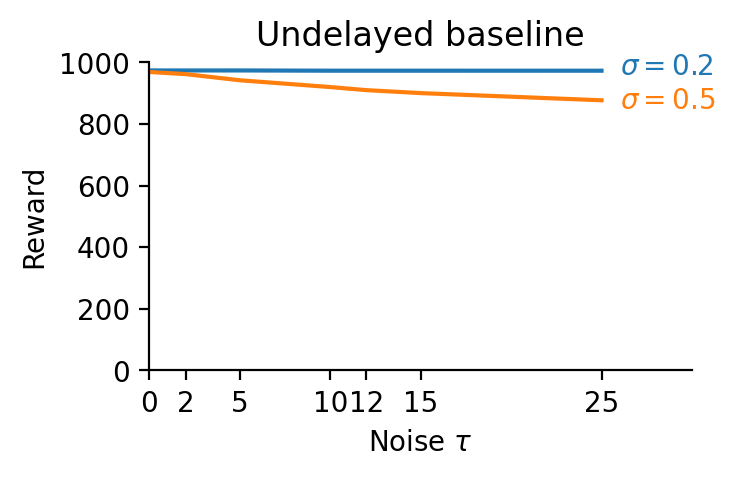

In [36]:
plt.figure(figsize=(3.5, 2), dpi=200)
sns.lineplot(data=undelayed, x="noise_tau", y="reward", hue="noise_std", palette=["C0", "C1"], legend=False)
plt.ylim(0, 1000)
plt.xticks([0, 2, 5, 10, 12, 15, 25])
plt.xlim(0, 30)
plt.text(26, 960, "$\\sigma=0.2$", color="C0")
plt.text(26, 850, "$\\sigma=0.5$", color="C1")
plt.ylabel("Reward")
plt.xlabel("Noise $\\tau$")
plt.title("Undelayed baseline")
sns.despine()

/tmp/ipykernel_445301/40446521.py:2: RuntimeWarning: divide by zero encountered in divide
  rho = np.exp(-1/taus)


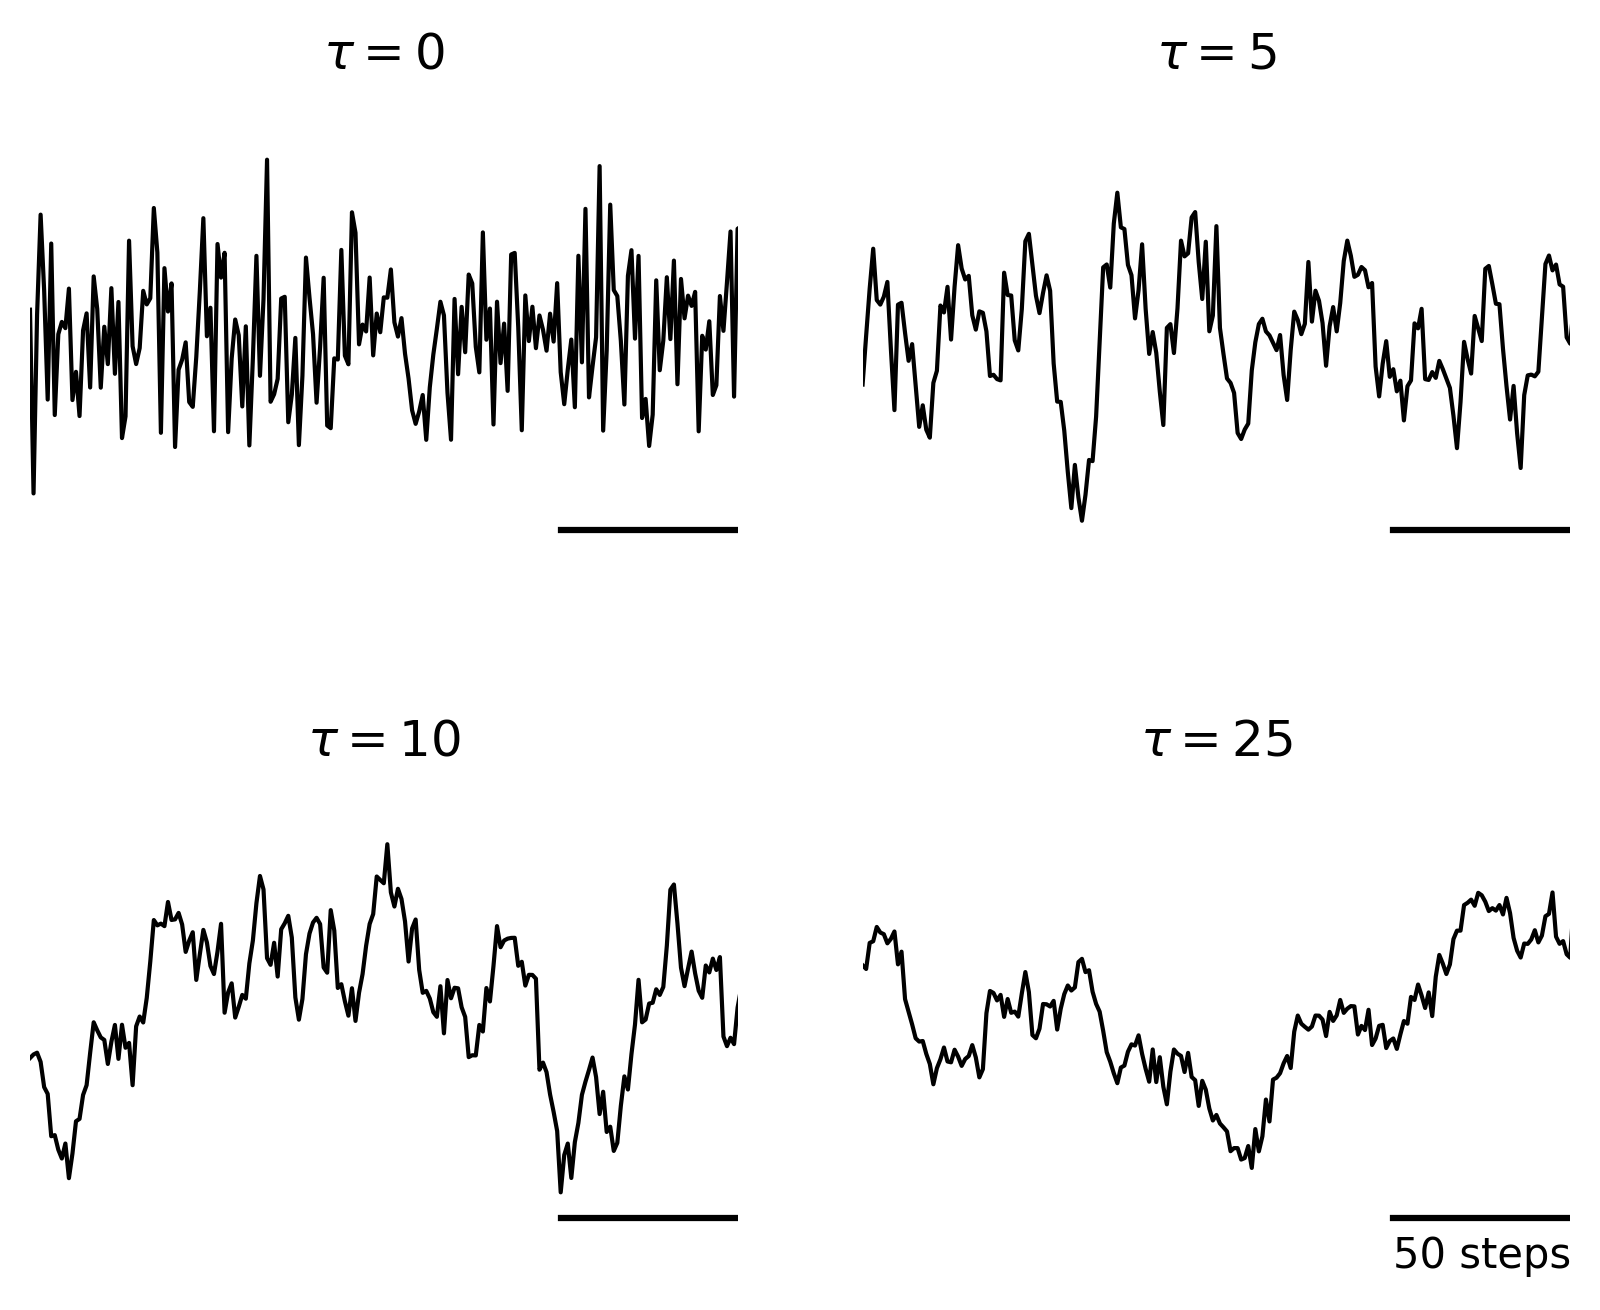

In [71]:
taus = np.array([0, 5, 10, 25])
rho = np.exp(-1/taus)
rho[0] = 0
y = np.zeros((1000, 4))
y[0] = np.random.normal(0, 0.5, size=4)
for t in range(1, 1000):
    y[t] = rho * y[t-1] + np.sqrt(1 - rho**2)*np.random.normal(0, 0.5, size=4)

fig, axs = plt.subplots(2, 2, figsize=(6, 5), dpi=300)#fig_kw={"fig_size": (6, 4), "dpi": 300})
for i in range(4):
    axs.flat[i].plot(y[:, i], 'k', lw=1)
    axs.flat[i].set_xlim(0, 200)
    axs.flat[i].set_ylim(-2, 2)
    axs.flat[i].axis("off")
    axs.flat[i].set_title(f"$\\tau={taus[i]}$")
    axs.flat[i].plot([150, 200], [-1.5, -1.5], 'k')
axs.flat[3].text(175, -1.9, '50 steps', ha="center")
#sns.despine(fig=fig)
plt.tight_layout(pad=3)

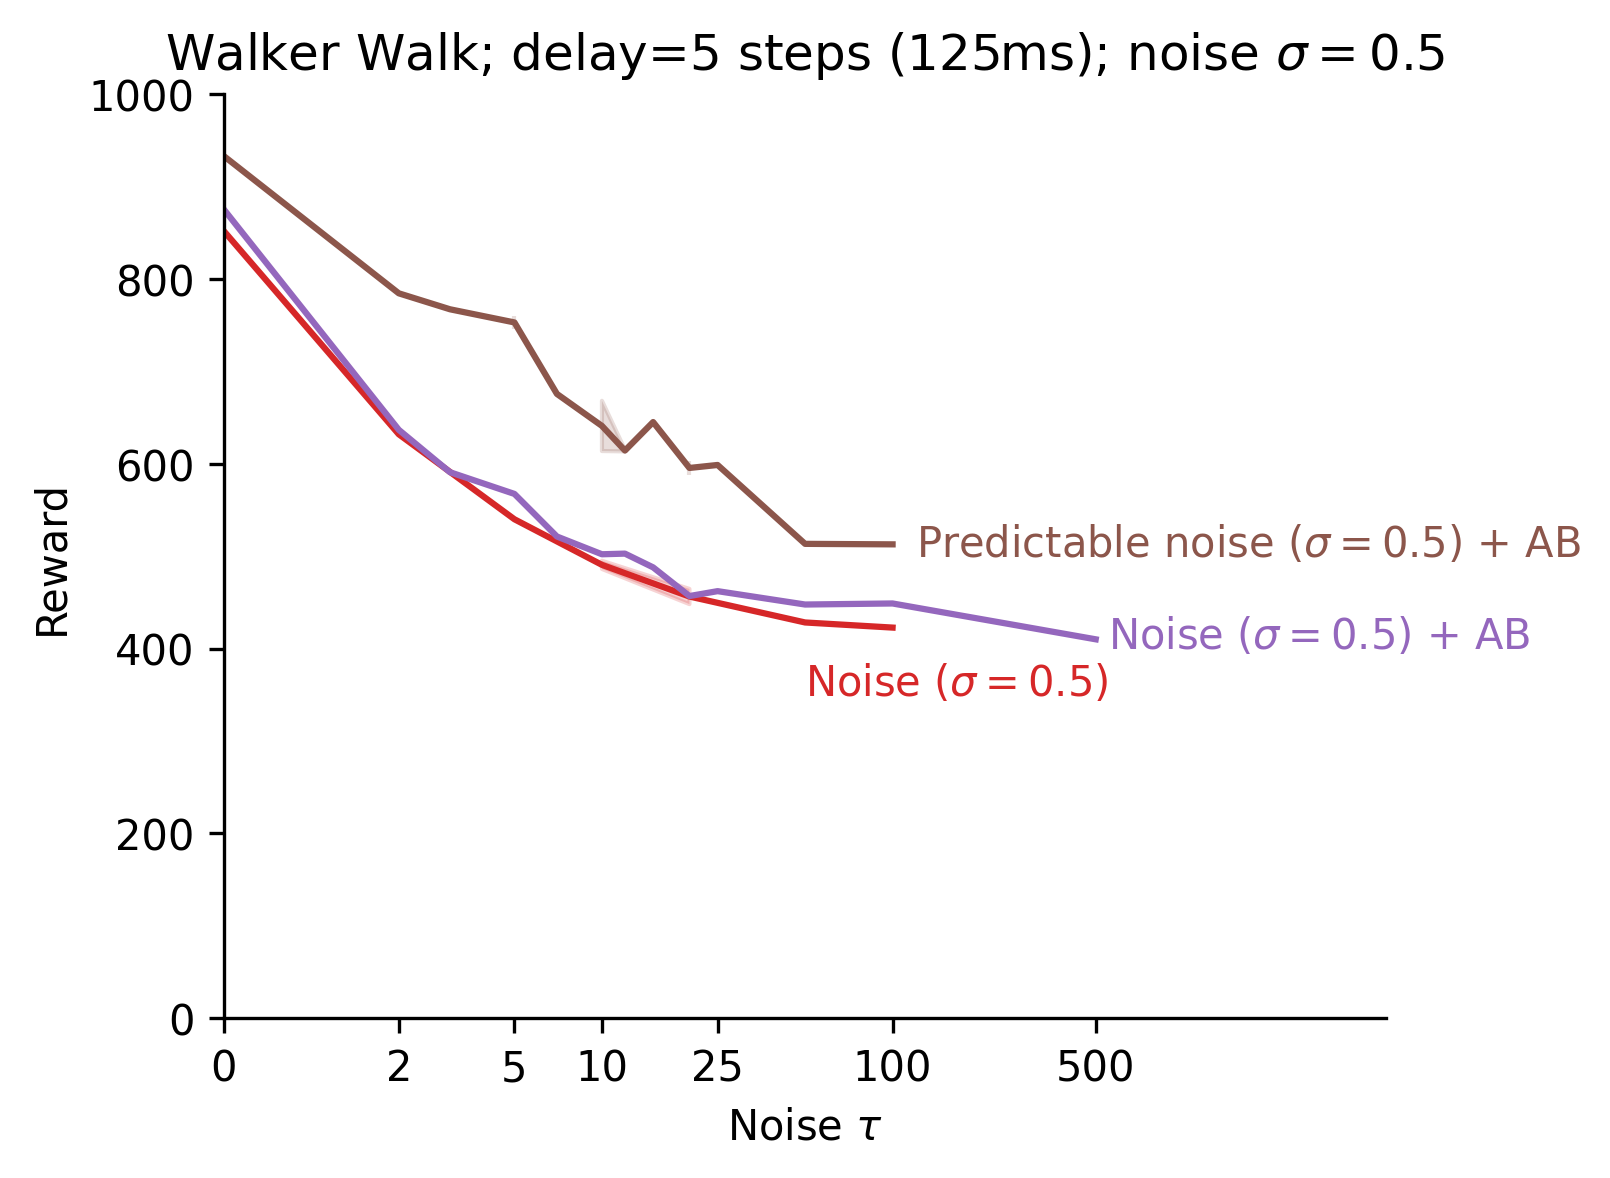

In [106]:
plt.figure(figsize=(5, 4), dpi=300)
d = data[(data.delay_k==5) * (data.noise_std==0.5)].copy()
d.loc[d.noise_tau==0, "noise_tau"] = 0.5
sns.lineplot(data=d, x="noise_tau", y="reward", hue="arm", palette=["C3", "C4", "C5"],legend=False)
plt.xscale("log")
plt.ylim(0, 1000)
plt.ylabel("Reward")
plt.xlabel("Noise $\\tau$")
plt.xticks([0.5, 2, 5, 10, 25, 100, 500], [0, 2, 5, 10, 25, 100, 500])
plt.xticks([], minor=True)
plt.xlim(0.5, 5000)
plt.title("Walker Walk; delay=5 steps (125ms); noise $\\sigma=0.5$")
plt.text(120, 500, "Predictable noise ($\\sigma=0.5$) + AB", color="C5")
plt.text(550, 400, "Noise ($\\sigma=0.5$) + AB", color="C4")
plt.text(50, 350, "Noise ($\\sigma=0.5$)", color="C3")
sns.despine()

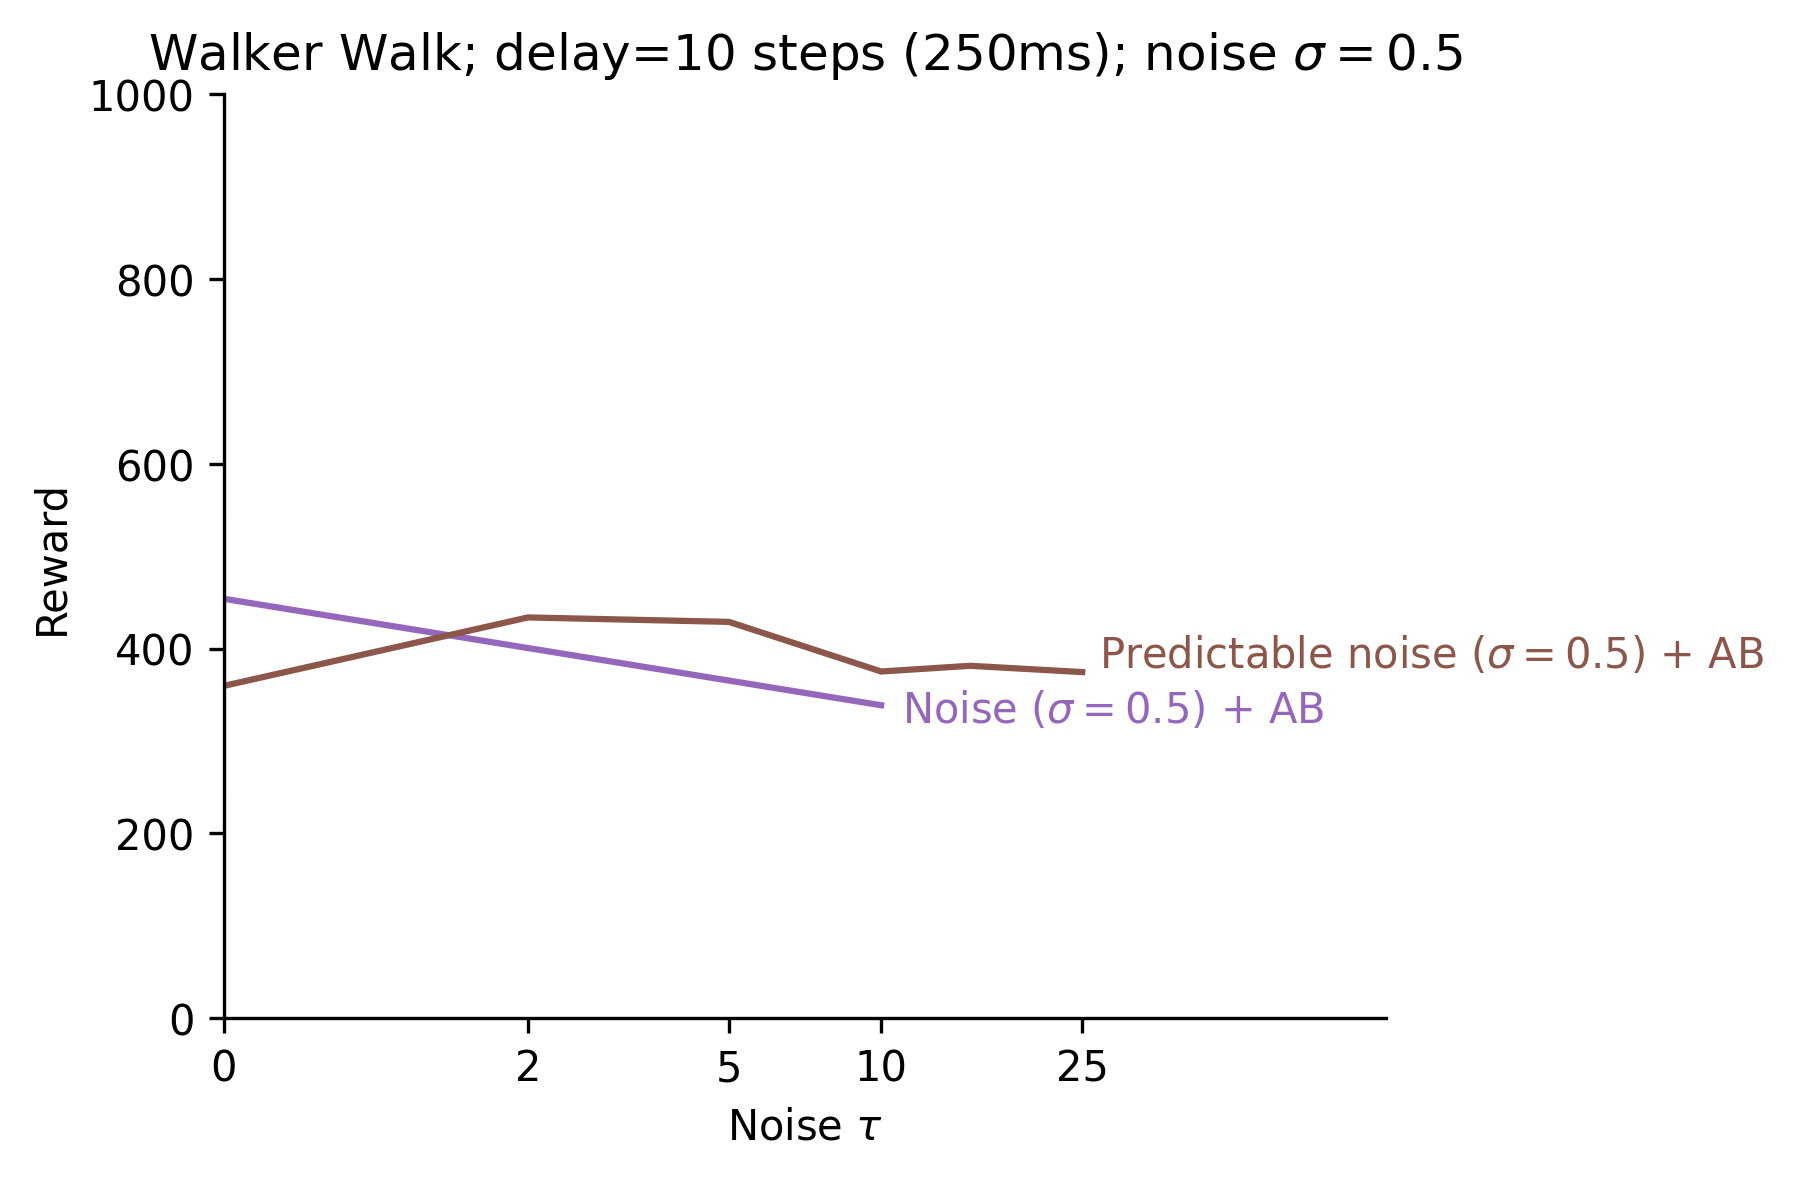

In [117]:
plt.figure(figsize=(5, 4), dpi=300)
d = data[(data.delay_k==10) * (data.noise_std==0.5)].copy()
d.loc[d.noise_tau==0, "noise_tau"] = 0.5
sns.lineplot(data=d, x="noise_tau", y="reward", hue="arm", palette=["C3", "C4", "C5"],legend=False)
plt.xscale("log")
plt.ylim(0, 1000)
plt.ylabel("Reward")
plt.xlabel("Noise $\\tau$")
plt.xticks([0.5, 2, 5, 10, 25], [0, 2, 5, 10, 25])
plt.xticks([], minor=True)
plt.xlim(0.5, 100)
plt.title("Walker Walk; delay=10 steps (250ms); noise $\\sigma=0.5$")
plt.text(27, 380, "Predictable noise ($\\sigma=0.5$) + AB", color="C5")
plt.text(11, 320, "Noise ($\\sigma=0.5$) + AB", color="C4")
#plt.text(50, 350, "Noise ($\\sigma=0.5$)", color="C3")
sns.despine()

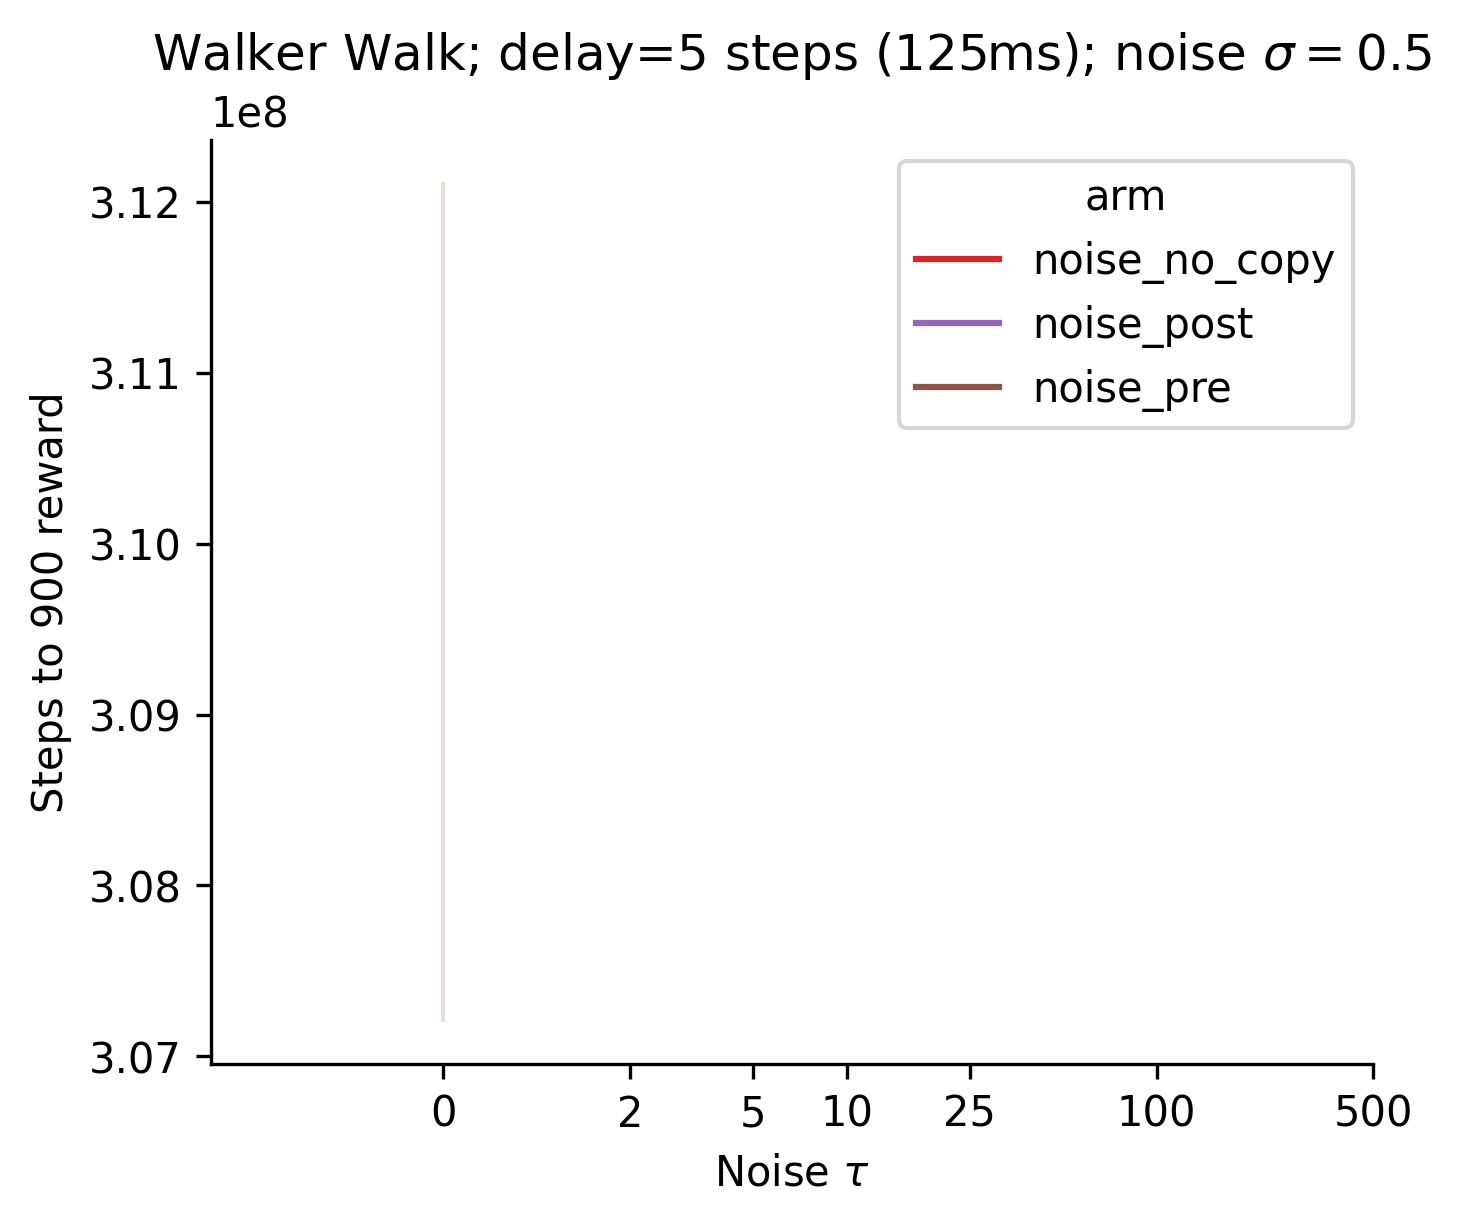

In [120]:
plt.figure(figsize=(5, 4), dpi=300)
d = data[(data.delay_k==5) * (data.noise_std==0.5)].copy()
d.loc[d.noise_tau==0, "noise_tau"] = 0.5
sns.lineplot(data=d, x="noise_tau", y="steps_to_900", hue="arm", palette=["C3", "C4", "C5"],legend=True)
plt.xscale("log")
#plt.ylim(0, 1000)
plt.ylabel("Steps to 900 reward")
plt.xlabel("Noise $\\tau$")
plt.xticks([0.5, 2, 5, 10, 25, 100, 500], [0, 2, 5, 10, 25, 100, 500])
plt.xticks([], minor=True)
#plt.xlim(0.5, 5000)
plt.title("Walker Walk; delay=5 steps (125ms); noise $\\sigma=0.5$")
#plt.text(120, 500, "Predictable noise ($\\sigma=0.5$) + AB", color="C5")
#plt.text(550, 400, "Noise ($\\sigma=0.5$) + AB", color="C4")
#plt.text(50, 350, "Noise ($\\sigma=0.5$)", color="C3")
sns.despine()

In [121]:
curves = pd.read_csv("curves.csv")

array([6.0e+07, 1.2e+08, 1.8e+08, 2.4e+08, 3.0e+08, 3.6e+08, 4.2e+08,
       4.8e+08])

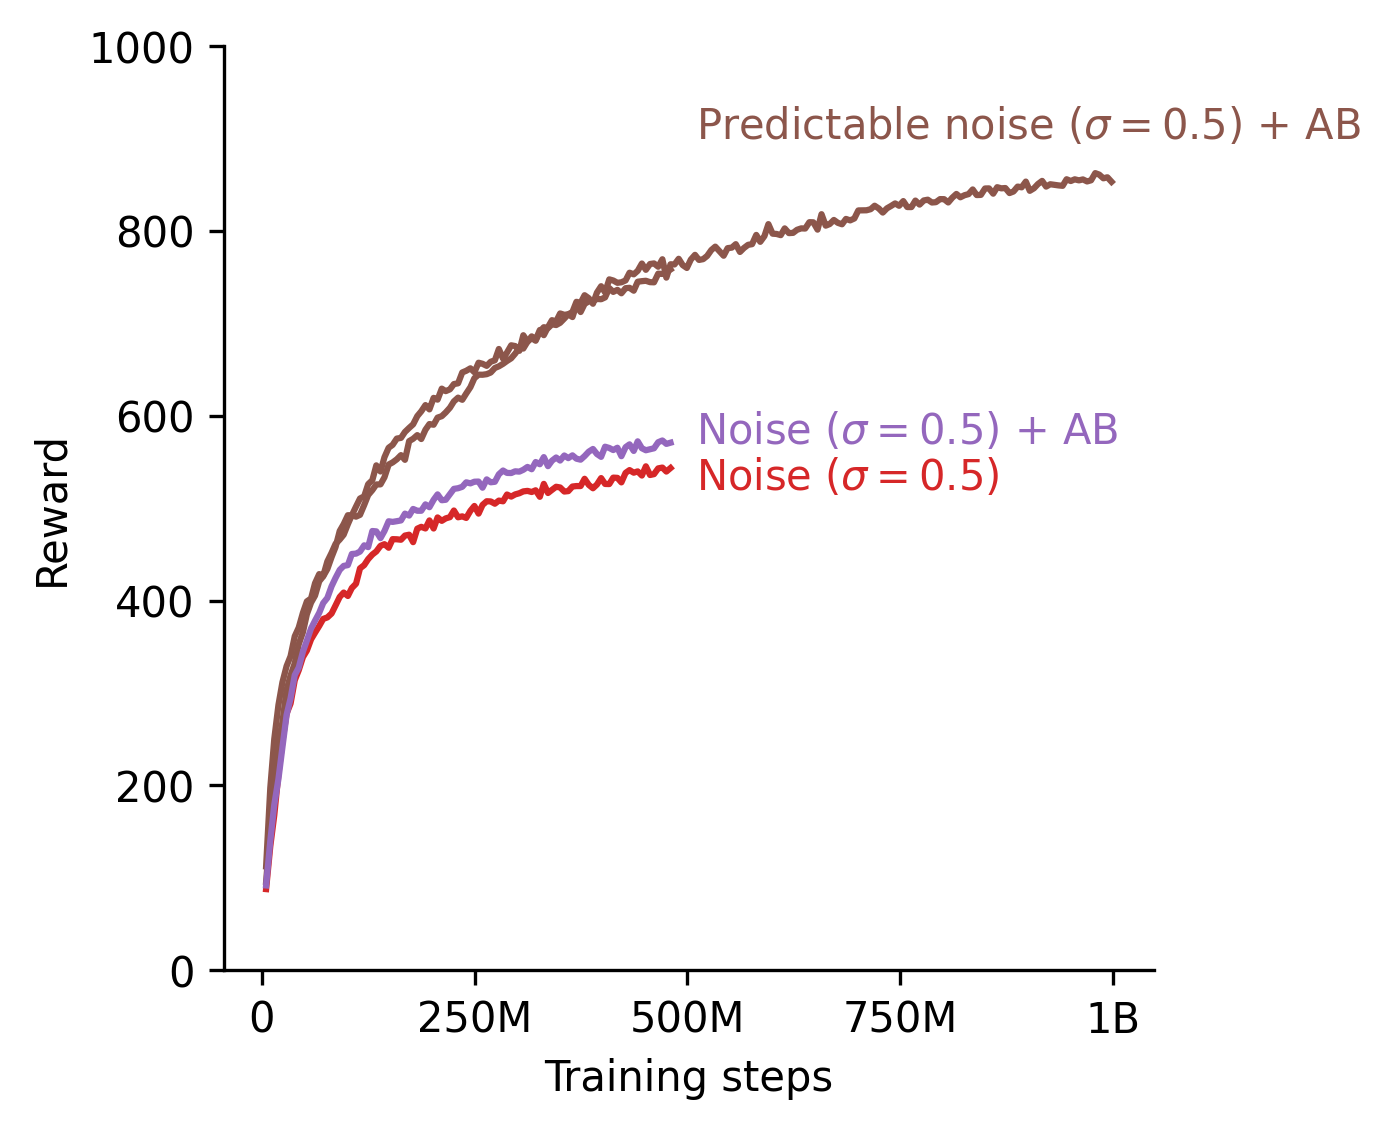

In [153]:
plt.figure(figsize=(4, 4), dpi=300)
d = curves[(curves.arm=="noise_no_copy") & (curves.delay_k==5) &
           (curves.noise_tau==5) & (curves.noise_std==0.5)]
plt.plot(d.step, d.reward, color="C3")

d = curves[(curves.arm=="noise_pre") & (curves.delay_k==5) &
           (curves.noise_tau==5) & (curves.noise_std==0.5)]
for (_, gb) in d.groupby("wandb_id"):
    plt.plot(gb.step, gb.reward, color="C5")

d = curves[(curves.arm=="noise_post") & (curves.delay_k==5) &
           (curves.noise_tau==5) & (curves.noise_std==0.5)]
for (_, gb) in d.groupby("wandb_id"):
    plt.plot(gb.step, gb.reward, color="C4")


plt.ylim(0, 1000)
plt.ylabel("Reward")
xticks = np.arange(0, 1001, 250)
plt.xticks(xticks*1e6, [0] + [f"{x}M" for x in xticks[1:-1]] + ["1B"])
plt.xlabel("Training steps")
plt.text(5.1e8, 900, "Predictable noise ($\\sigma=0.5$) + AB", color="C5")
plt.text(5.1e8, 570, "Noise ($\\sigma=0.5$) + AB", color="C4")
plt.text(5.1e8, 520, "Noise ($\\sigma=0.5$)", color="C3")
sns.despine()

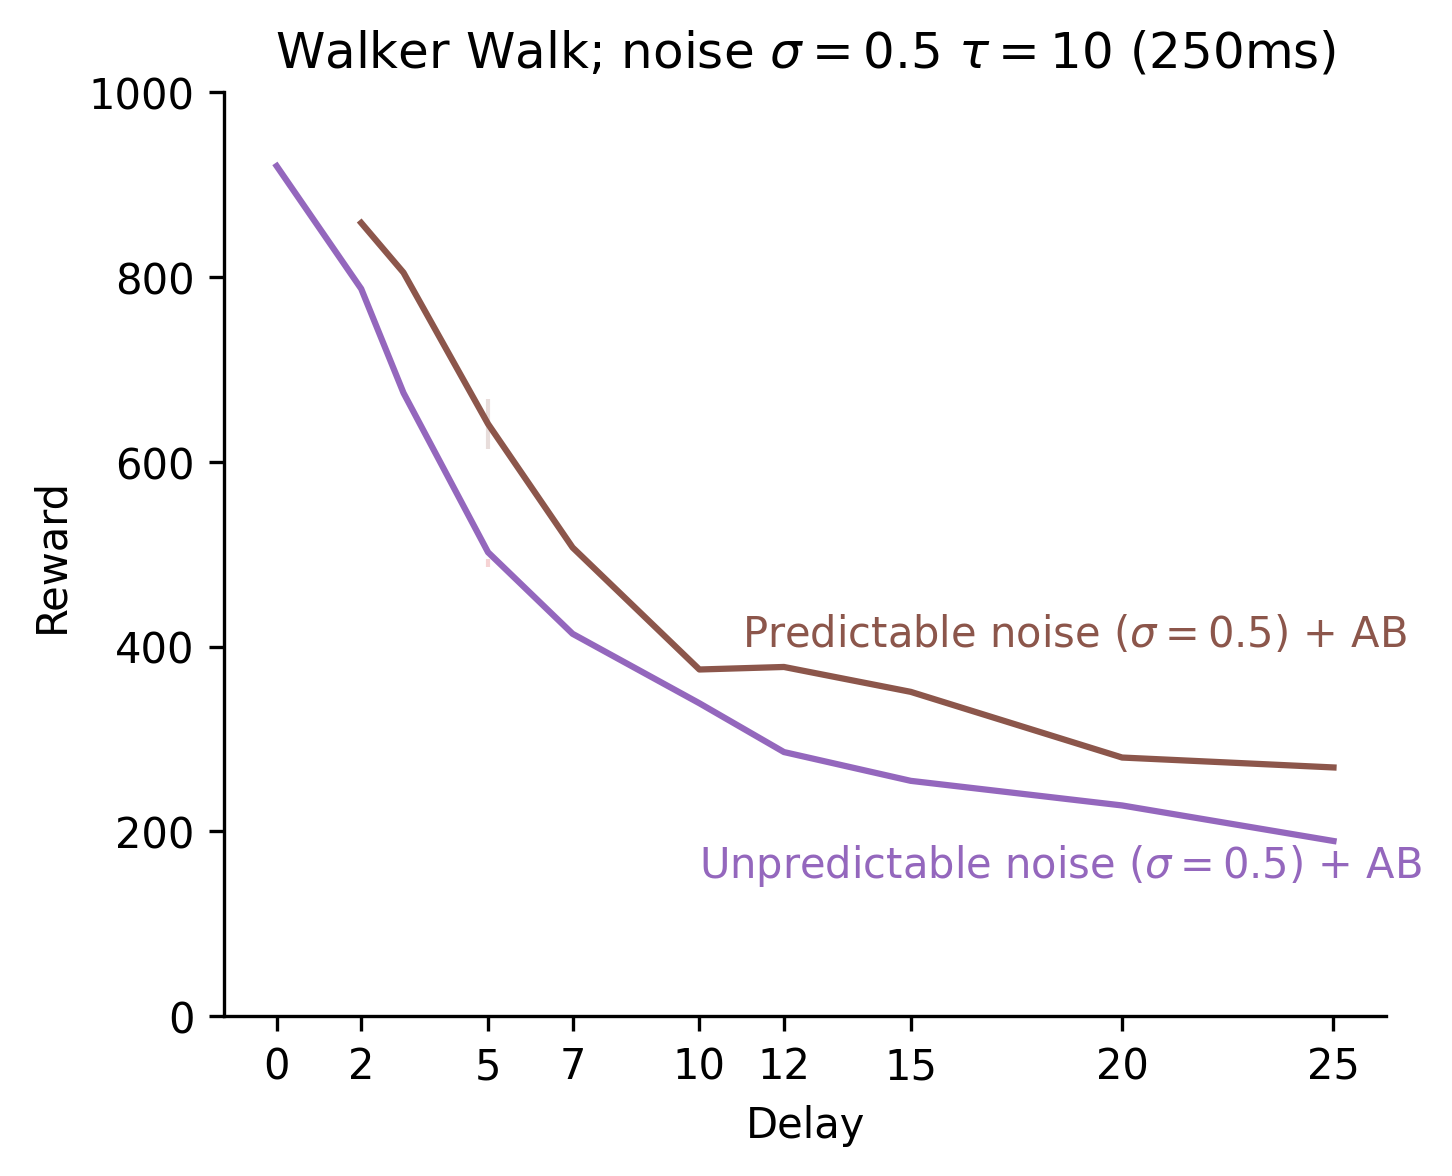

In [168]:
plt.figure(figsize=(5, 4), dpi=300)
d = data[(data.noise_tau==10) * (data.noise_std==0.5)].copy()
sns.lineplot(data=d, x="delay_k", y="reward", hue="arm", palette=["C3", "C4", "C5"],legend=False)
plt.ylim(0, 1000)
plt.ylabel("Reward")
plt.xlabel("Delay")
plt.xticks([0, 2, 5, 7, 10, 12, 15, 20, 25])
plt.xticks([], minor=True)
#plt.xlim(0.5, 5000)
plt.title("Walker Walk; noise $\\sigma=0.5$ $\\tau=10$ (250ms)")
plt.text(11, 400, "Predictable noise ($\\sigma=0.5$) + AB", color="C5")
plt.text(10, 150, "Unpredictable noise ($\\sigma=0.5$) + AB", color="C4")
#plt.text(5, 350, "Noise ($\\sigma=0.5$)", color="C3")
sns.despine()